# CA1 – Data Visualisation and Communication
## Employment in AI, Data Science and Software Development in the USA (May 2023)

**Student:** Carlos Eduardo Sabino Accioly Silva – 2023319

**Lecturer:** Taufique Ahmed

**GitHub repository:** https://github.com/CarlosAccioly/Ca1-DataVisu

**Video presentation (4 min):** https://drive.google.com/file/d/1guajsi2aQb6r6UGIsXlPUAZLQXwH8by9/view?usp=sharing

**Dataset:** U.S. Bureau of Labor Statistics (2024) *Occupational Employment and Wage Statistics, May 2023*. Available at: https://www.bls.gov/oes/tables.htm

In [1]:
   import pandas as pd
   import matplotlib.pyplot as plt
   import seaborn as sns
   import openpyxl
   print("All libraries loaded!")

All libraries loaded!


In [2]:
# Load the May 2023 OEWS dataset (U.S. Bureau of Labor Statistics).
# The Excel file is slow to read, so a local copy (.pkl) is saved the first time
# and reused in later sessions.
import os

if os.path.exists("oews_2023.pkl"):
    df = pd.read_pickle("oews_2023.pkl")
else:
    df = pd.read_excel("all_data_M_2023.xlsx")
    df.to_pickle("oews_2023.pkl")

print("Rows and columns:", df.shape)
df.head()

Rows and columns: (413327, 32)


,AREA,AREA_TITLE,AREA_TYPE,PRIM_STATE,NAICS,NAICS_TITLE,I_GROUP,OWN_CODE,OCC_CODE,OCC_TITLE,...,H_MEDIAN,H_PCT75,H_PCT90,A_PCT10,A_PCT25,A_MEDIAN,A_PCT75,A_PCT90,ANNUAL,HOURLY
0,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,00-0000,All Occupations,...,23.11,37.01,58.4,29050,35660,48060,76980,121470,NaN,NaN
1,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-0000,Management Occupations,...,56.19,81.29,111.36,54550,78330,116880,169090,231620,NaN,NaN
2,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1000,Top Executives,...,49.74,79.57,#,46400,66170,103460,165500,#,NaN,NaN
3,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1010,Chief Executives,...,99.37,#,#,80000,130840,206680,#,#,NaN,NaN
4,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1011,Chief Executives,...,99.37,#,#,80000,130840,206680,#,#,NaN,NaN


In [3]:
# 1) Keep national figures only (whole U.S.), all industries combined, detailed occupations
national = df[(df["AREA_TYPE"] == 1) &
              (df["NAICS"] == "000000") &
              (df["O_GROUP"] == "detailed")].copy()

# 2) Occupations related to AI, Data Science and Software Development (SOC codes),
#    grouped into four fields
occupation_groups = {
    "15-1221": "AI & Research",              # Computer and Information Research Scientists
    "15-2051": "Data Science & Analytics",   # Data Scientists
    "15-2041": "Data Science & Analytics",   # Statisticians
    "15-2031": "Data Science & Analytics",   # Operations Research Analysts
    "15-1242": "Data Science & Analytics",   # Database Administrators
    "15-1243": "Data Science & Analytics",   # Database Architects
    "15-1252": "Software Development",       # Software Developers
    "15-1253": "Software Development",       # Software QA Analysts and Testers
    "15-1251": "Software Development",       # Computer Programmers
    "15-1254": "Software Development",       # Web Developers
    "15-1211": "IT Systems & Management",    # Computer Systems Analysts
    "11-3021": "IT Systems & Management",    # Computer and Information Systems Managers
}

tech = national[national["OCC_CODE"].isin(occupation_groups.keys())].copy()
tech["GROUP"] = tech["OCC_CODE"].map(occupation_groups)

# 3) Convert numbers stored as text into real numbers
#    (the BLS uses "*" for missing values and "#" for wages above $239,200)
numeric_cols = ["TOT_EMP", "A_MEAN", "A_MEDIAN", "A_PCT10", "A_PCT25",
                "A_PCT75", "A_PCT90", "H_MEDIAN"]
for col in numeric_cols:
    tech[col] = pd.to_numeric(tech[col], errors="coerce")

tech = tech.sort_values("TOT_EMP", ascending=False)
tech[["OCC_TITLE", "GROUP", "TOT_EMP", "A_MEDIAN"]]

,OCC_TITLE,GROUP,TOT_EMP,A_MEDIAN
149,Software Developers,Software Development,1656880,132270
23,Computer and Information Systems Managers,IT Systems & Management,592600,169510
135,Computer Systems Analysts,IT Systems & Management,498810,103800
150,Software Quality Assurance Analysts and Testers,Software Development,203040,101800
165,Data Scientists,Data Science & Analytics,192710,108020
148,Computer Programmers,Software Development,120370,99700
161,Operations Research Analysts,Data Science & Analytics,117880,83640
151,Web Developers,Software Development,85350,84960
144,Database Administrators,Data Science & Analytics,76140,101510
145,Database Architects,Data Science & Analytics,59920,134700


In [4]:
# One fixed colour per field, used in every chart so the reader can follow each field
group_colors = {
    "AI & Research": "#2a78d6",             # blue
    "Data Science & Analytics": "#eb6834",  # orange
    "Software Development": "#1baf7a",      # green
    "IT Systems & Management": "#eda100",   # yellow
}
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

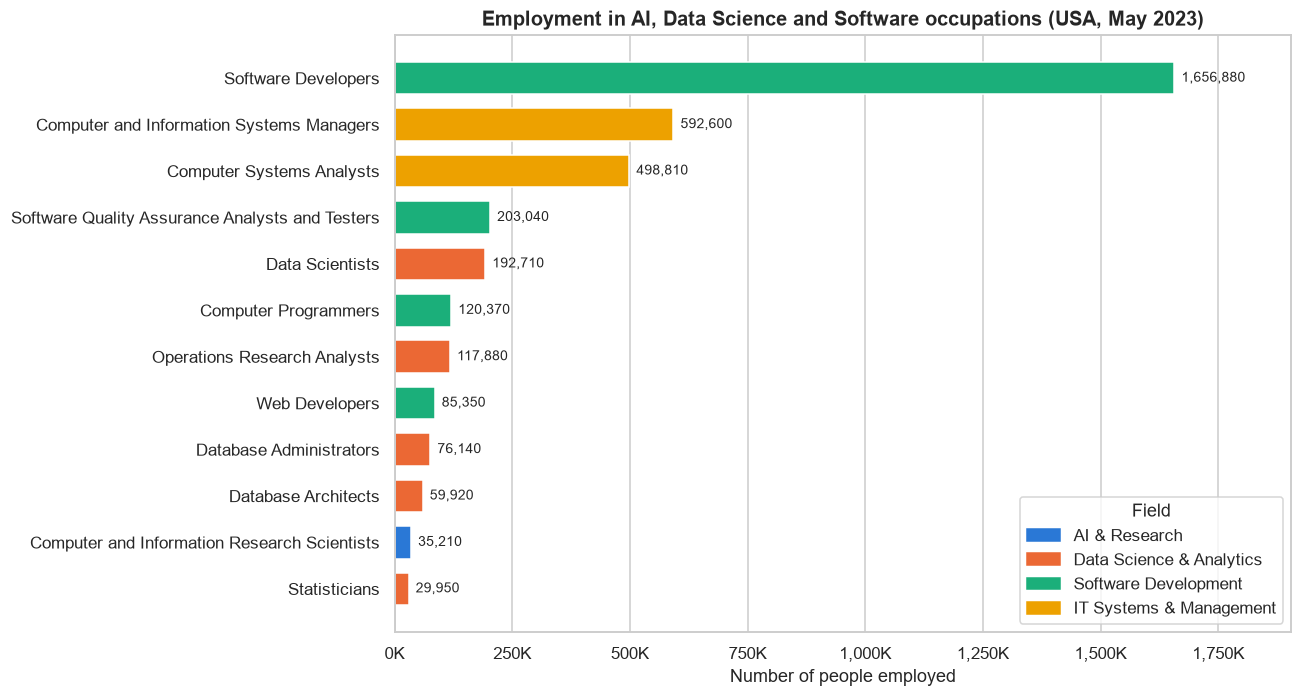

In [5]:
# Visualisation 1: employment by occupation (horizontal bar chart)
chart1 = tech.sort_values("TOT_EMP")   # smallest at the bottom, largest at the top

fig, ax = plt.subplots(figsize=(12, 6.5))
bars = ax.barh(chart1["OCC_TITLE"], chart1["TOT_EMP"],
               color=chart1["GROUP"].map(group_colors), height=0.7)

# Write the number of jobs at the end of each bar
for bar, value in zip(bars, chart1["TOT_EMP"]):
    ax.text(value + 15000, bar.get_y() + bar.get_height() / 2,
            f"{value:,.0f}", va="center", fontsize=9)

ax.set_title("Employment in AI, Data Science and Software occupations (USA, May 2023)",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Number of people employed")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f"{x/1000:,.0f}K"))
ax.set_xlim(0, chart1["TOT_EMP"].max() * 1.15)
ax.grid(axis="y", visible=False)

# Legend: one colour per field
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in group_colors.values()]
ax.legend(handles, group_colors.keys(), title="Field", loc="lower right")

plt.tight_layout()
plt.show()

In [6]:
# Key figures used in the explanation below
total = tech["TOT_EMP"].sum()
software_devs = tech.loc[tech["OCC_CODE"] == "15-1252", "TOT_EMP"].iloc[0]
data_scientists = tech.loc[tech["OCC_CODE"] == "15-2051", "TOT_EMP"].iloc[0]

print(f"Total employment in the 12 occupations: {total:,.0f}")
print(f"Software Developers share: {software_devs / total:.1%}")
print(f"Software Developers vs Data Scientists: {software_devs / data_scientists:.1f}x")

Total employment in the 12 occupations: 3,668,860
Software Developers share: 45.2%
Software Developers vs Data Scientists: 8.6x


### Visualisation 1 – Horizontal bar chart: employment by occupation

**Objective:** *Comparison.* To compare how many people work in each of the 12 occupations and identify which roles employ the most people.

**Why this chart type:** The data has one categorical variable (occupation) and one numeric variable (number of employees). A bar chart is the clearest way to compare sizes across categories, because the eye compares bar lengths very accurately. I used horizontal bars so the long occupation names stay readable, and sorted them from largest to smallest so the ranking is visible immediately. Each bar is coloured by field, and the same colours are used in every chart in this notebook.

**What I learned:** Software Developers dominate this group, with 1,656,880 jobs – 45.2% of the 3.67 million jobs across the 12 occupations and about 8.6 times more than Data Scientists (192,710). The occupation most directly linked to AI, Computer and Information Research Scientists, employs only 35,210 people, one of the smallest groups in the chart. The BLS does not have a separate "AI engineer" occupation, so AI work is spread across several categories, mainly research scientists, data scientists and software developers.

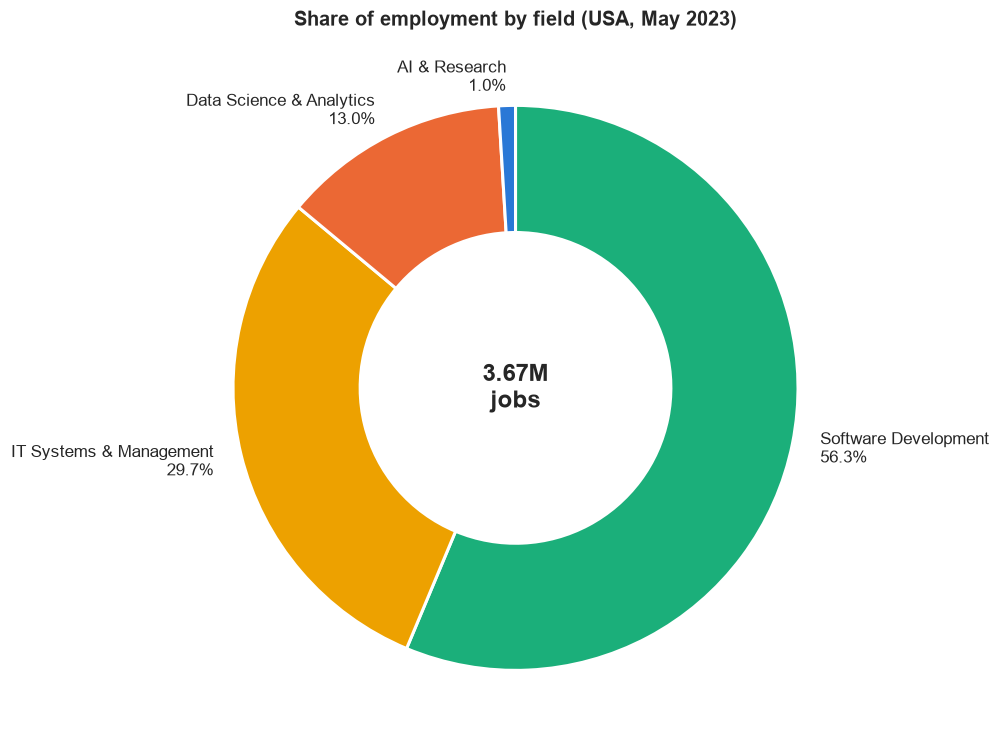

GROUP
Software Development        2065640
IT Systems & Management     1091410
Data Science & Analytics     476600
AI & Research                 35210
Name: TOT_EMP, dtype: int64

In [7]:
# Visualisation 2: share of employment by field (donut chart)
group_totals = tech.groupby("GROUP")["TOT_EMP"].sum().sort_values(ascending=False)
shares = group_totals / group_totals.sum() * 100
labels = [f"{group}\n{share:.1f}%" for group, share in zip(group_totals.index, shares)]

fig, ax = plt.subplots(figsize=(10, 7))
ax.pie(
    group_totals,
    labels=labels,
    colors=[group_colors[g] for g in group_totals.index],
    startangle=90,
    counterclock=False,
    wedgeprops={"width": 0.45, "edgecolor": "white", "linewidth": 2},   # donut style
    textprops={"fontsize": 11},
)
ax.text(0, 0, f"{group_totals.sum()/1e6:.2f}M\njobs", ha="center", va="center",
        fontsize=16, fontweight="bold")
ax.set_title("Share of employment by field (USA, May 2023)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

group_totals

### Visualisation 2 – Donut chart: share of employment by field

**Objective:** *Composition.* To show how total employment in these occupations is divided between the four fields.

**Why this chart type:** This is a part-to-whole question with only four categories that add up to 100%, which is where a pie or donut chart works best. With many slices a pie becomes hard to read, so I first grouped the 12 occupations into four fields. I chose a donut rather than a full pie because the empty centre shows the total (3.67 million jobs), and the percentages are written next to each slice so the reader does not have to estimate angles.

**What I learned:** Software Development accounts for more than half of the jobs (56.3%, about 2.07 million), followed by IT Systems & Management (29.7%) and Data Science & Analytics (13.0%). AI & Research is only 1.0% (35,210 jobs) – the slice is so thin it is hard to see, which is itself the main insight: in 2023 the specialist AI research workforce in the USA was still very small compared with traditional software roles, and most AI-related work is probably done by people classified as software developers or data scientists.

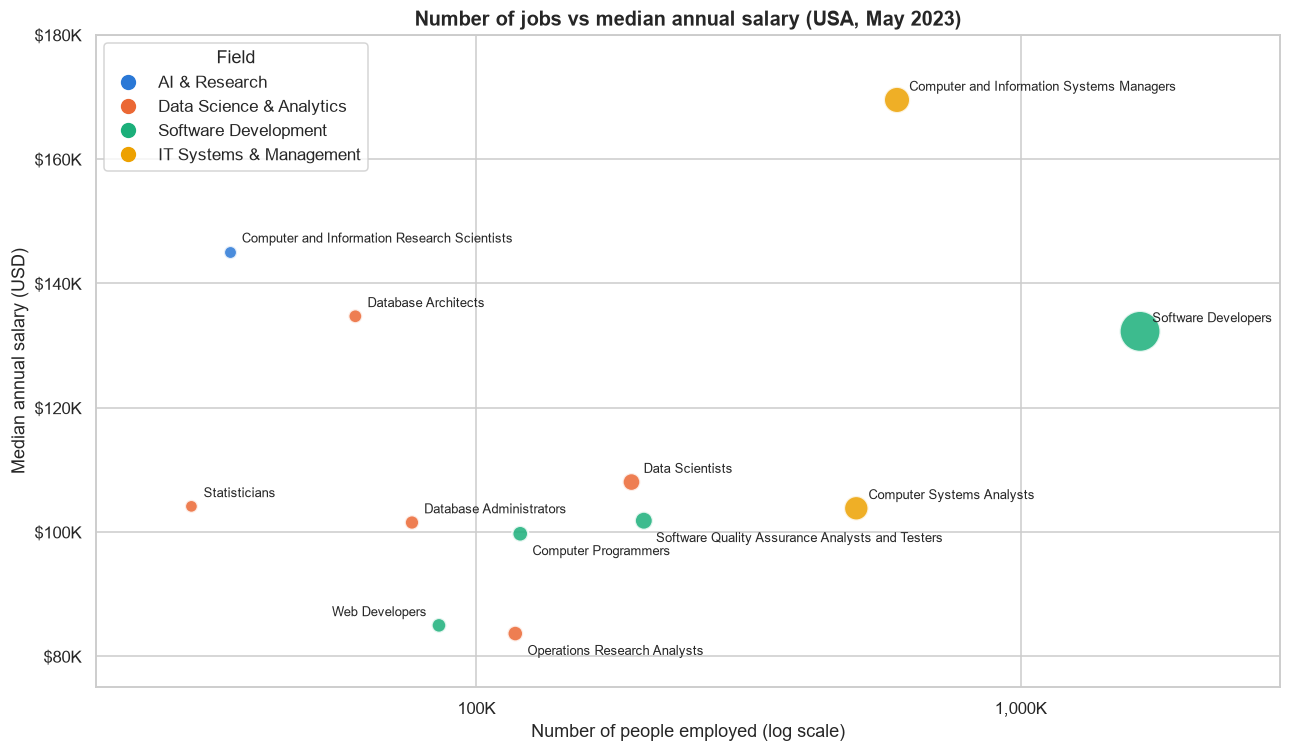

In [8]:
# Visualisation 3: employment vs median salary (scatter / bubble chart)
fig, ax = plt.subplots(figsize=(12, 7))
for group, color in group_colors.items():
    subset = tech[tech["GROUP"] == group]
    ax.scatter(subset["TOT_EMP"], subset["A_MEDIAN"],
               s=subset["TOT_EMP"] / 2500 + 60,     # bubble size grows with employment
               color=color, alpha=0.85, edgecolor="white", linewidth=1.5, label=group)

# Label every point with its occupation name
# (a few labels are moved below or to the left so they do not overlap)
label_offsets = {
    "Software Quality Assurance Analysts and Testers": (8, -14, "left"),
    "Computer Programmers": (8, -14, "left"),
    "Operations Research Analysts": (8, -14, "left"),
    "Web Developers": (-8, 6, "right"),
}
for _, row in tech.iterrows():
    dx, dy, align = label_offsets.get(row["OCC_TITLE"], (8, 6, "left"))
    ax.annotate(row["OCC_TITLE"], (row["TOT_EMP"], row["A_MEDIAN"]),
                xytext=(dx, dy), textcoords="offset points", fontsize=8.5, ha=align)

ax.set_xscale("log")   # log scale, because Software Developers are much larger than the rest
ax.set_title("Number of jobs vs median annual salary (USA, May 2023)",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Number of people employed (log scale)")
ax.set_ylabel("Median annual salary (USD)")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f"{x/1000:,.0f}K"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, p: f"${y/1000:,.0f}K"))
ax.set_xlim(20000, 3000000)
ax.set_ylim(75000, 180000)
legend_dots = [plt.Line2D([0], [0], marker="o", linestyle="", markersize=9, color=c)
               for c in group_colors.values()]
ax.legend(legend_dots, group_colors.keys(), title="Field", loc="upper left")
plt.tight_layout()
plt.show()

In [9]:
# Key figures used in the explanation below
corr = tech["TOT_EMP"].corr(tech["A_MEDIAN"])
print(f"Correlation between employment and median salary: {corr:.2f}")
tech[["OCC_TITLE", "TOT_EMP", "A_MEDIAN"]].sort_values("A_MEDIAN", ascending=False)

Correlation between employment and median salary: 0.36


,OCC_TITLE,TOT_EMP,A_MEDIAN
23,Computer and Information Systems Managers,592600,169510
138,Computer and Information Research Scientists,35210,145080
145,Database Architects,59920,134700
149,Software Developers,1656880,132270
165,Data Scientists,192710,108020
163,Statisticians,29950,104110
135,Computer Systems Analysts,498810,103800
150,Software Quality Assurance Analysts and Testers,203040,101800
144,Database Administrators,76140,101510
148,Computer Programmers,120370,99700


### Visualisation 3 – Scatter (bubble) chart: number of jobs vs median salary

**Objective:** *Relationship / investigation.* To investigate whether the occupations with the most jobs are also the best paid.

**Why this chart type:** Both variables are numeric (employment and median annual salary), and a scatter plot is the standard way to show the relationship between two numeric variables. The bubble size repeats the number of jobs so large occupations stand out, and the colours are the same fields used in the previous charts. I used a logarithmic x-axis because Software Developers (1.66 million) are so much larger than the other occupations that, on a normal scale, all the other points would be squeezed together on the left.

**What I learned:** The correlation between the number of jobs and the median salary is only 0.36, so a large occupation is not necessarily a well-paid one. The best-paid group is Computer and Information Systems Managers ($169,510), followed by Computer and Information Research Scientists ($145,080) – the AI-related occupation is one of the smallest (35,210 jobs) but the second best paid, which suggests strong demand for a small pool of specialists. Software Developers combine both size and high pay ($132,270). Data Scientists earn a median of $108,020, while Web Developers ($84,960) and Operations Research Analysts ($83,640) are the lowest paid in this group.

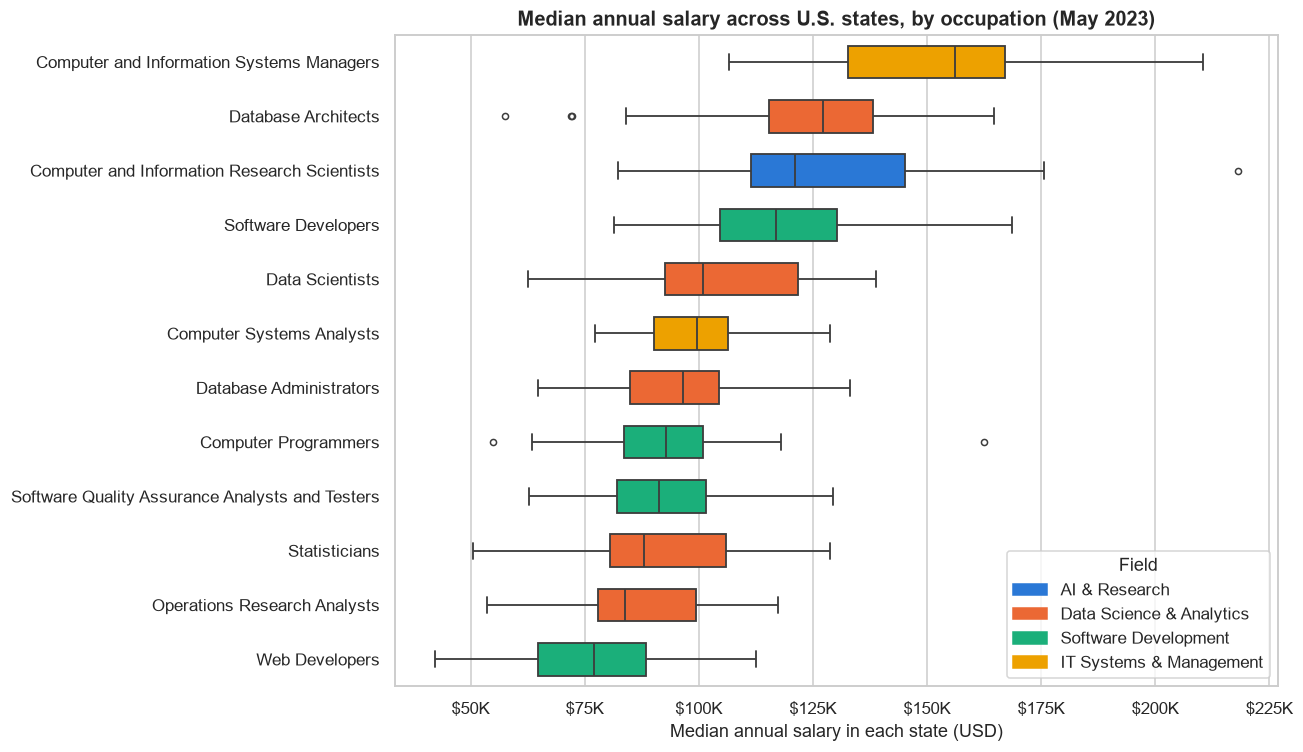

In [10]:
# State-level data: one row per occupation per state, all industries combined
states = df[(df["AREA_TYPE"] == 2) &
            (df["NAICS"] == "000000") &
            (df["OCC_CODE"].isin(occupation_groups.keys()))].copy()
states["GROUP"] = states["OCC_CODE"].map(occupation_groups)
for col in ["TOT_EMP", "A_MEDIAN", "JOBS_1000", "LOC_QUOTIENT"]:
    states[col] = pd.to_numeric(states[col], errors="coerce")

# Visualisation 4: how median salaries vary between states (box plot)
order = states.groupby("OCC_TITLE")["A_MEDIAN"].median().sort_values(ascending=False).index
palette = {title: group_colors[occupation_groups[code]]
           for code, title in zip(tech["OCC_CODE"], tech["OCC_TITLE"])}

fig, ax = plt.subplots(figsize=(12, 7))
sns.boxplot(data=states, y="OCC_TITLE", x="A_MEDIAN", order=order,
            hue="OCC_TITLE", palette=palette, legend=False,
            width=0.6, fliersize=4, linewidth=1.2, saturation=1, ax=ax)
ax.set_title("Median annual salary across U.S. states, by occupation (May 2023)",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Median annual salary in each state (USD)")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f"${x/1000:,.0f}K"))

handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in group_colors.values()]
ax.legend(handles, group_colors.keys(), title="Field", loc="lower right")
plt.tight_layout()
plt.show()

In [11]:
# Key figures used in the explanation below
spread = states.groupby("OCC_TITLE")["A_MEDIAN"].agg(["min", "median", "max", "count"])
spread["range"] = spread["max"] - spread["min"]
spread.sort_values("median", ascending=False).round(0)

,min,median,max,count,range
OCC_TITLE,,,,,
Computer and Information Systems Managers,106690.0,156135.0,210490.0,50,103800.0
Database Architects,57610.0,127230.0,164720.0,51,107110.0
Computer and Information Research Scientists,82360.0,121060.0,218180.0,42,135820.0
Software Developers,81380.0,116830.0,168660.0,51,87280.0
Data Scientists,62600.0,100950.0,138780.0,51,76180.0
Computer Systems Analysts,77210.0,99680.0,128710.0,50,51500.0
Database Administrators,64830.0,96560.0,133200.0,51,68370.0
Computer Programmers,55000.0,92850.0,162440.0,49,107440.0
Software Quality Assurance Analysts and Testers,62730.0,91240.0,129400.0,49,66670.0


### Visualisation 4 – Box plot: how median salaries vary between U.S. states

**Objective:** *Distribution / comparison.* To show how much the salary of the same occupation changes depending on the state, and to compare that variation between occupations.

**Why this chart type:** For each occupation there are around 50 values (one median salary per state, including Washington DC). A box plot summarises a whole distribution in a small space – the line in the box is the middle state, the box holds the middle 50% of states, the whiskers show the normal range and the dots are outliers. This makes it possible to compare 12 distributions side by side, which would be impossible with 12 separate histograms. The occupations are sorted by their typical salary and coloured by field.

**What I learned:** Location matters almost as much as the job title. Data Scientists earn a median of $62,600 in Mississippi but $138,780 in Delaware – more than double. The AI-related occupation, Computer and Information Research Scientists, has the widest range of all, from $82,360 (Indiana) to $218,180 (Washington State), and Washington appears as a clear outlier, which is consistent with large technology companies being based there. IT Systems Managers are the best paid in almost every state, while Web Developers are consistently at the bottom. One limitation is that the BLS does not publish every occupation in every state (Research Scientists only appear in 42 states).

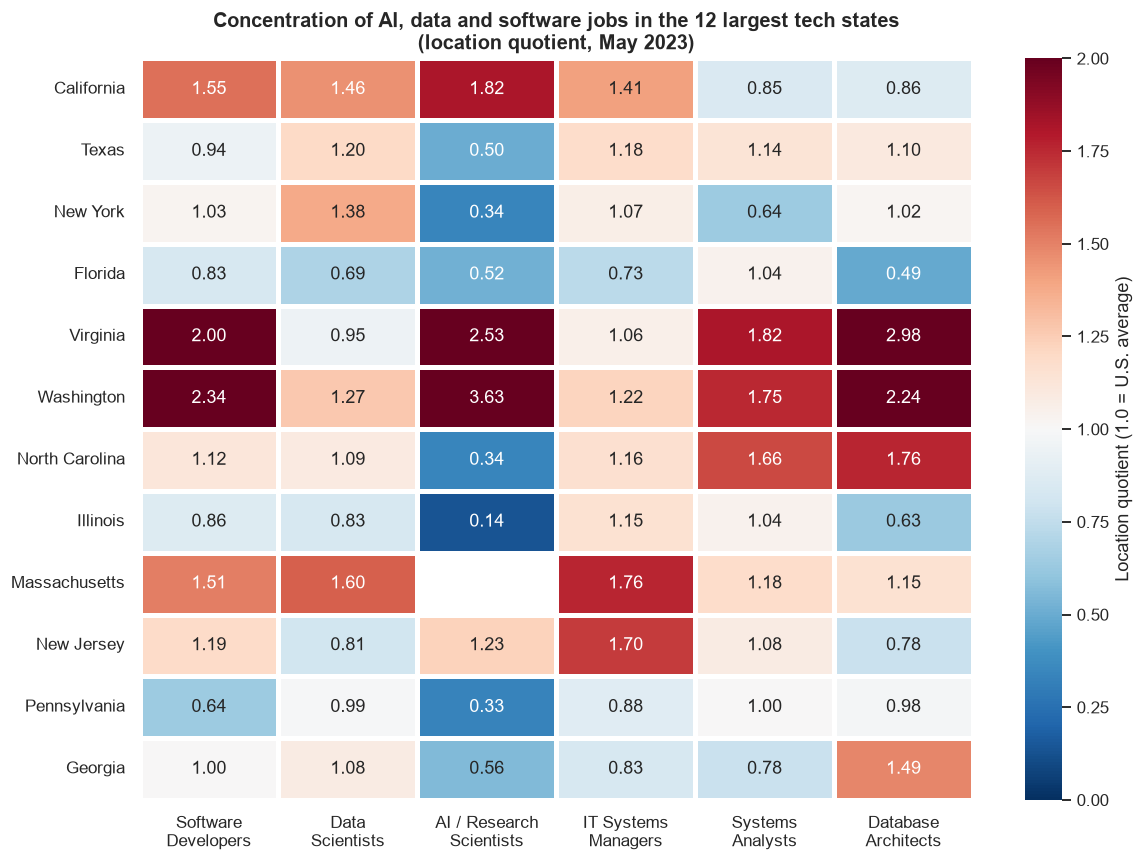

In [12]:
# Visualisation 5: where the jobs are concentrated (heatmap)
# Top 12 states by total employment in the 12 occupations
top_states = states.groupby("AREA_TITLE")["TOT_EMP"].sum().nlargest(12).index

key_occupations = ["Software Developers", "Data Scientists",
                   "Computer and Information Research Scientists",
                   "Computer and Information Systems Managers",
                   "Computer Systems Analysts", "Database Architects"]

heat = (states[states["AREA_TITLE"].isin(top_states) & states["OCC_TITLE"].isin(key_occupations)]
        .pivot_table(index="AREA_TITLE", columns="OCC_TITLE", values="LOC_QUOTIENT")
        .reindex(index=top_states, columns=key_occupations))

short_names = {"Computer and Information Research Scientists": "AI / Research\nScientists",
               "Computer and Information Systems Managers": "IT Systems\nManagers",
               "Computer Systems Analysts": "Systems\nAnalysts",
               "Software Developers": "Software\nDevelopers",
               "Data Scientists": "Data\nScientists",
               "Database Architects": "Database\nArchitects"}

fig, ax = plt.subplots(figsize=(11, 8))
# Location quotient: 1.0 = same share of jobs as the U.S. average,
# above 1 = more concentrated than average (red), below 1 = less concentrated (blue)
sns.heatmap(heat.rename(columns=short_names), annot=True, fmt=".2f",
            cmap="RdBu_r", center=1, vmin=0, vmax=2,
            linewidths=2, linecolor="white",
            cbar_kws={"label": "Location quotient (1.0 = U.S. average)"}, ax=ax)
ax.set_title("Concentration of AI, data and software jobs in the 12 largest tech states\n(location quotient, May 2023)",
             fontsize=13, fontweight="bold")
ax.set_xlabel("")
ax.set_ylabel("")
ax.grid(False)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Visualisation 5 – Heatmap: where AI, data and software jobs are concentrated

**Objective:** *Comparison across two dimensions.* To identify which states specialise in which occupations, using the 12 states with the most jobs in these fields.

**Why this chart type:** The data is a grid – states on one axis, occupations on the other, and one number in each cell – and a heatmap shows the whole grid at once, so patterns jump out through colour. I used the location quotient instead of the raw number of jobs, because raw numbers would just show that California is the biggest state. A location quotient of 1.0 means the state has the same share of that job as the U.S. average, so a diverging colour scale was chosen: red above average, blue below, and white at 1.0. The exact value is written in every cell so the chart does not rely on colour alone.

**What I learned:** AI research jobs are highly concentrated in a few places. Washington State has 3.63 times the national share of Computer and Information Research Scientists and 2.34 times the share of Software Developers, Virginia has 2.53 for research scientists and 2.98 for Database Architects, and California has 1.82. In contrast, large states such as Illinois (0.14) and Pennsylvania (0.33) have very few AI research jobs relative to their size. This shows that AI employment is not spread evenly across the country but clustered in a small number of technology hubs. The empty cell for Massachusetts is a value the BLS did not publish.

## Challenge – AI employment trends over time (2021–2024)

To explore how employment in these occupations has changed over time, I downloaded the national data files for May 2021, May 2022, May 2023 and May 2024 from the BLS OEWS tables page and combined them with the same 12 occupations used above.

I started the comparison in 2021 on purpose. Until May 2020 the BLS used older occupation codes: Data Scientists did not exist as a separate occupation (code 15-2051) and Software Developers were combined with Software QA Testers. Using those years would compare different groups of workers, so 2021 is the first year where all 12 occupations are directly comparable.

**Sources:**
- U.S. Bureau of Labor Statistics (2022) *Occupational Employment and Wage Statistics, May 2021: National*. Available at: https://www.bls.gov/oes/tables.htm (Accessed: 29 October 2026).
- U.S. Bureau of Labor Statistics (2023) *Occupational Employment and Wage Statistics, May 2022: National*. Available at: https://www.bls.gov/oes/tables.htm (Accessed: 29 October 2026).
- U.S. Bureau of Labor Statistics (2024) *Occupational Employment and Wage Statistics, May 2023: National*. Available at: https://www.bls.gov/oes/tables.htm (Accessed: 29 October 2026).
- U.S. Bureau of Labor Statistics (2025) *Occupational Employment and Wage Statistics, May 2024: National*. Available at: https://www.bls.gov/oes/tables.htm (Accessed: 29 October 2026).

In [13]:
# Challenge: load the national OEWS files for other years (downloaded from https://www.bls.gov/oes/tables.htm)
import glob
import zipfile

yearly = []
for path in sorted(glob.glob("oesm*nat.zip")):
    year = 2000 + int(path[4:6])                      # "oesm21nat.zip" -> 2021
    with zipfile.ZipFile(path) as z:
        excel_name = [n for n in z.namelist() if n.endswith(".xlsx")][0]
        data = pd.read_excel(z.open(excel_name))
    data.columns = data.columns.str.upper()           # make column names consistent between years
    data = data[(data["O_GROUP"] == "detailed") & (data["OCC_CODE"].isin(occupation_groups.keys()))]
    data = data[["OCC_CODE", "OCC_TITLE", "TOT_EMP", "A_MEDIAN"]].copy()
    data["YEAR"] = year
    yearly.append(data)
    print(f"{year}: {len(data)} occupations loaded from {path}")

trend = pd.concat(yearly, ignore_index=True)
trend["GROUP"] = trend["OCC_CODE"].map(occupation_groups)
for col in ["TOT_EMP", "A_MEDIAN"]:
    trend[col] = pd.to_numeric(trend[col], errors="coerce")

# Use the 2023 titles for every year, so the names match across files
trend["OCC_TITLE"] = trend["OCC_CODE"].map(dict(zip(tech["OCC_CODE"], tech["OCC_TITLE"])))
first_year, last_year = trend["YEAR"].min(), trend["YEAR"].max()

trend.pivot_table(index="OCC_TITLE", columns="YEAR", values="TOT_EMP").sort_values(last_year, ascending=False)

2021: 12 occupations loaded from oesm21nat.zip
2022: 12 occupations loaded from oesm22nat.zip
2023: 12 occupations loaded from oesm23nat.zip
2024: 12 occupations loaded from oesm24nat.zip


YEAR,2021,2022,2023,2024
OCC_TITLE,,,,
Software Developers,1364180.0,1534790.0,1656880.0,1654440.0
Computer and Information Systems Managers,485190.0,533220.0,592600.0,645970.0
Computer Systems Analysts,505150.0,505210.0,498810.0,497800.0
Data Scientists,105980.0,159630.0,192710.0,233440.0
Software Quality Assurance Analysts and Testers,190120.0,196420.0,203040.0,199800.0
Computer Programmers,152610.0,132740.0,120370.0,109870.0
Operations Research Analysts,98700.0,105080.0,117880.0,107760.0
Web Developers,84820.0,88620.0,85350.0,78860.0
Database Administrators,85870.0,80520.0,76140.0,73180.0


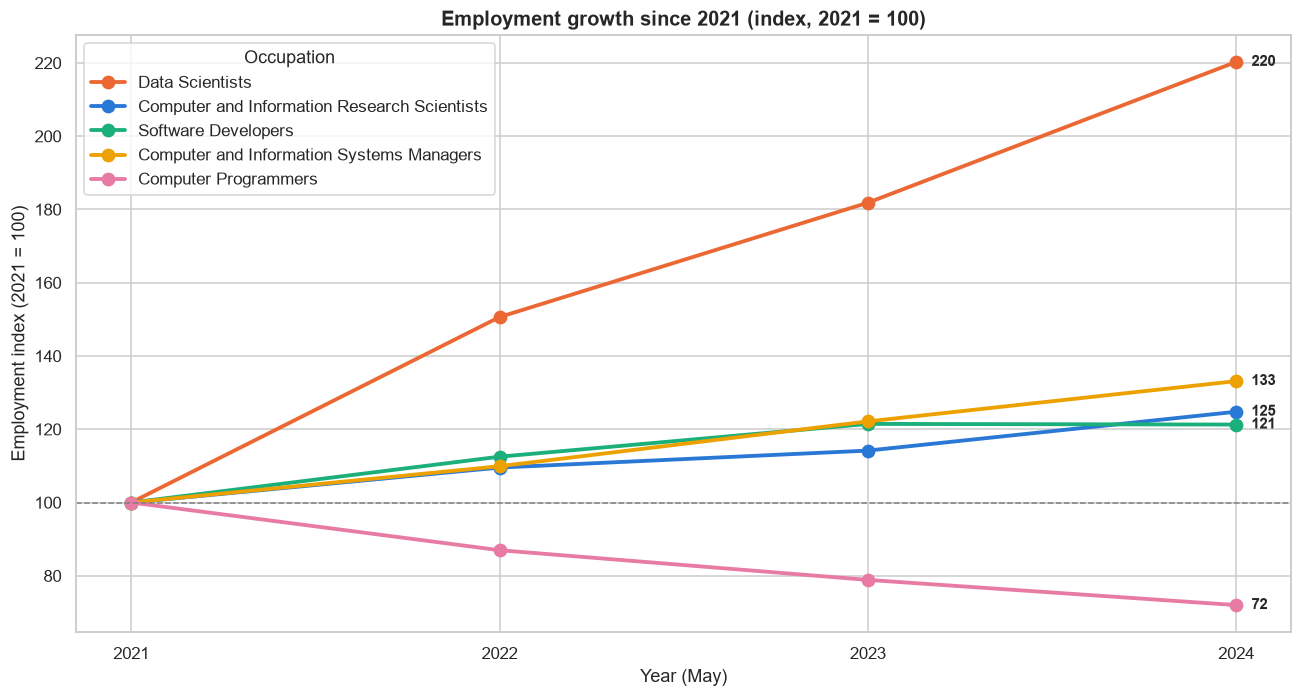

In [14]:
# Visualisation 6: employment growth over time, indexed so the first year = 100 (line chart)
selected = {
    "Data Scientists": "#eb6834",
    "Computer and Information Research Scientists": "#2a78d6",
    "Software Developers": "#1baf7a",
    "Computer and Information Systems Managers": "#eda100",
    "Computer Programmers": "#e87ba4",
}
index_table = trend.pivot_table(index="YEAR", columns="OCC_TITLE", values="TOT_EMP")
index_table = index_table / index_table.loc[first_year] * 100   # first year = 100

fig, ax = plt.subplots(figsize=(12, 6.5))
for title, color in selected.items():
    ax.plot(index_table.index, index_table[title], marker="o", linewidth=2.5,
            markersize=8, color=color, label=title)
    last_value = index_table[title].iloc[-1]
    ax.annotate(f"{last_value:.0f}", (index_table.index[-1], last_value),
                xytext=(10, 0), textcoords="offset points", va="center",
                fontsize=10, fontweight="bold")

ax.axhline(100, color="grey", linewidth=1, linestyle="--")
ax.set_title(f"Employment growth since {first_year} (index, {first_year} = 100)",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Year (May)")
ax.set_ylabel(f"Employment index ({first_year} = 100)")
ax.set_xticks(index_table.index)
ax.legend(title="Occupation", loc="upper left")
plt.tight_layout()
plt.show()

### Visualisation 6 – Line chart: employment growth since 2021

**Objective:** *Trend over time.* To see which occupations grew or shrank between 2021 and 2024.

**Why this chart type:** A line chart is the standard choice for change over time, because the slope of each line shows the direction and speed of change. The occupations have very different sizes (1.65 million Software Developers against 38,000 Research Scientists), so on a normal axis the small ones would look flat. I therefore converted every series to an index where 2021 = 100, which puts all occupations on the same scale and keeps a single y-axis. The dashed line at 100 marks "no change", and the final value is written at the end of each line.

**What I learned:** Data Scientists are by far the fastest-growing occupation: employment rose from 105,980 in 2021 to 233,440 in 2024 (index 220), meaning it more than doubled in three years. Computer and Information Research Scientists, the occupation most linked to AI research, grew by 25% (from 30,840 to 38,480), and Software Developers by 21%, although their growth stopped between 2023 and 2024. In contrast, Computer Programmers fell by 28% (from 152,610 to 109,870). This suggests a shift in demand from traditional programming towards data and AI skills.

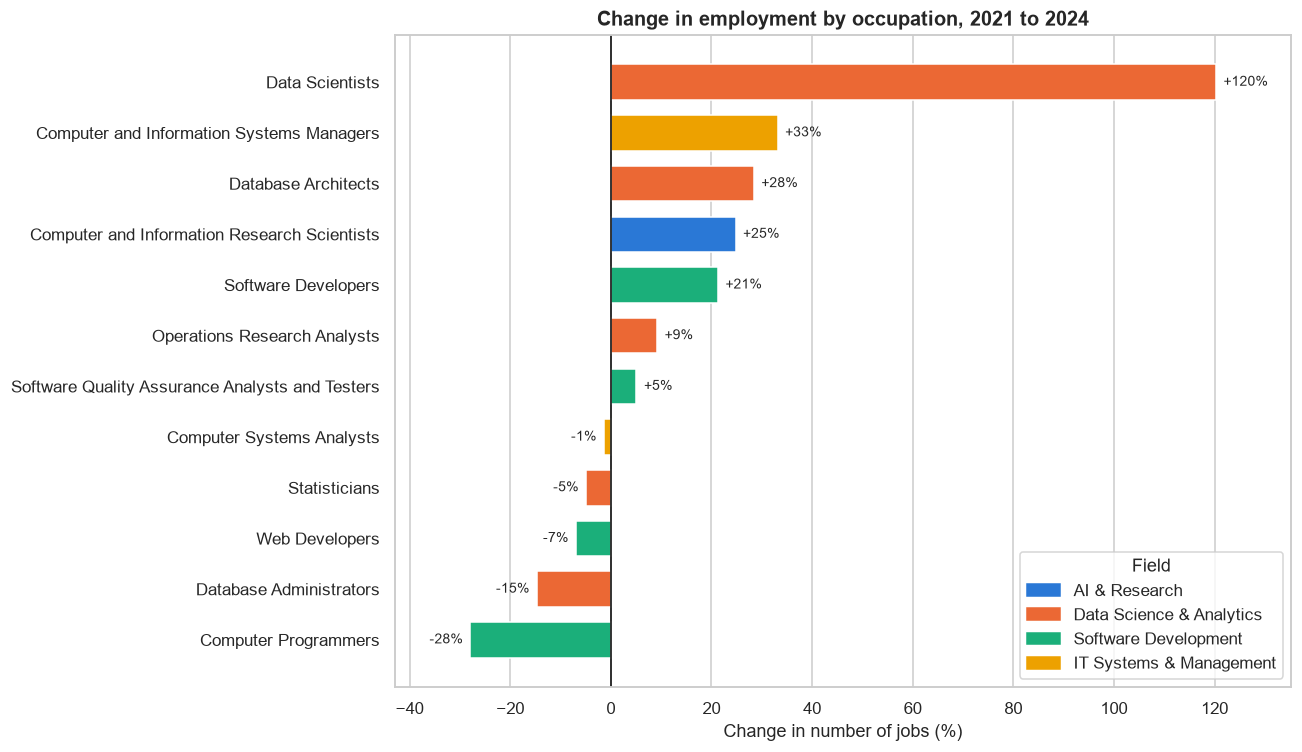

,Employment change (%),Median salary change (%),GROUP
OCC_TITLE,,,
Data Scientists,120.3,11.6,Data Science & Analytics
Computer and Information Systems Managers,33.1,7.7,IT Systems & Management
Database Architects,28.4,10.2,Data Science & Analytics
Computer and Information Research Scientists,24.8,7.2,AI & Research
Software Developers,21.3,10.2,Software Development
Operations Research Analysts,9.2,10.8,Data Science & Analytics
Software Quality Assurance Analysts and Testers,5.1,4.5,Software Development
Computer Systems Analysts,-1.5,4.6,IT Systems & Management
Statisticians,-5.0,8.1,Data Science & Analytics


In [15]:
# Visualisation 7: percentage change in employment for every occupation (diverging bar chart)
first = trend[trend["YEAR"] == first_year].set_index("OCC_TITLE")
last = trend[trend["YEAR"] == last_year].set_index("OCC_TITLE")
change = pd.DataFrame({
    "Employment change (%)": (last["TOT_EMP"] / first["TOT_EMP"] - 1) * 100,
    "Median salary change (%)": (last["A_MEDIAN"] / first["A_MEDIAN"] - 1) * 100,
    "GROUP": last["GROUP"],
}).sort_values("Employment change (%)")

fig, ax = plt.subplots(figsize=(12, 7))
bars = ax.barh(change.index, change["Employment change (%)"],
               color=change["GROUP"].map(group_colors), height=0.7)
for bar, value in zip(bars, change["Employment change (%)"]):
    ax.text(value + (1.5 if value >= 0 else -1.5), bar.get_y() + bar.get_height() / 2,
            f"{value:+.0f}%", va="center", ha="left" if value >= 0 else "right", fontsize=9)
ax.axvline(0, color="black", linewidth=1)
ax.set_title(f"Change in employment by occupation, {first_year} to {last_year}",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Change in number of jobs (%)")
ax.set_ylabel("")
ax.set_xlim(change["Employment change (%)"].min() - 15, change["Employment change (%)"].max() + 15)
ax.grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in group_colors.values()]
ax.legend(handles, group_colors.keys(), title="Field", loc="lower right")
plt.tight_layout()
plt.show()

change.sort_values("Employment change (%)", ascending=False).round(1)

### Visualisation 7 – Diverging bar chart: change in employment, 2021–2024

**Objective:** *Comparison of change.* To compare the growth or decline of all 12 occupations over the same period.

**Why this chart type:** The line chart can only show a few occupations before it becomes cluttered, so this bar chart shows all 12 at once. Because the values can be positive or negative, the bars start from a zero line – growth goes to the right and decline to the left – which makes winners and losers easy to separate. The bars are sorted and keep the same field colours as the rest of the notebook.

**What I learned:** 7 of the 12 occupations grew. Data Scientists (+120%) are far ahead, followed by IT Systems Managers (+33%), Database Architects (+28%), Computer and Information Research Scientists (+25%) and Software Developers (+21%). The occupations that shrank are mostly older or more routine technical roles: Computer Programmers (-28%), Database Administrators (-15%), Web Developers (-7%) and Statisticians (-5%).

**Challenge conclusion:** Between 2021 and 2024, employment in the USA moved towards data science and AI-related work. Data Scientists more than doubled and AI research jobs grew by a quarter, while traditional programming jobs declined. A limitation is that the BLS has no dedicated "AI engineer" occupation, so AI work is measured indirectly through these categories, and four years is still a short period for identifying long-term trends.

## Conclusion

This notebook used the BLS Occupational Employment and Wage Statistics to explore employment in AI, Data Science and Software Development in the USA. The main findings are:

1. **Software dominates, AI specialists are few.** Software Developers are the largest occupation by far (1,656,880 jobs, 45.2% of the 3.67 million jobs analysed), while Computer and Information Research Scientists – the occupation closest to AI research – account for only 35,210 jobs (1.0%). *(Visualisations 1 and 2)*
2. **Small does not mean badly paid.** The correlation between the size of an occupation and its median salary is only 0.36. AI research scientists are one of the smallest groups but the second best paid ($145,080), behind IT Systems Managers ($169,510). *(Visualisation 3)*
3. **Location matters as much as the job title.** The same occupation can pay twice as much in a different state – for example, Data Scientists earn $62,600 in Mississippi and $138,780 in Delaware – and AI research salaries range from $82,360 to $218,180. *(Visualisation 4)*
4. **AI jobs are concentrated in a few technology hubs.** Washington (3.63 times the national share), Virginia (2.53) and California (1.82) dominate AI research employment, while large states such as Illinois and Pennsylvania have very few of these jobs. *(Visualisation 5)*
5. **Demand is moving towards data and AI.** Between 2021 and 2024, Data Scientists more than doubled (+120%) and AI research jobs grew by 25%, while Computer Programmers fell by 28%. *(Visualisations 6 and 7)*

Overall, AI-related employment in the USA is still a small part of the technology workforce, but it is well paid, geographically concentrated and growing much faster than traditional programming roles.

**Limitations:** the BLS does not have a dedicated "AI engineer" or "machine learning engineer" occupation, so AI work had to be measured indirectly through related occupations. The OEWS survey does not include self-employed workers, some values are not published for smaller states, and the trend analysis covers only four years (2021–2024) because earlier years used different occupation codes.

## References

Hunter, J.D. (2007) 'Matplotlib: A 2D graphics environment', *Computing in Science & Engineering*, 9(3), pp. 90–95.

McKinney, W. (2010) 'Data structures for statistical computing in Python', *Proceedings of the 9th Python in Science Conference*, pp. 56–61.

U.S. Bureau of Labor Statistics (2022) *Occupational Employment and Wage Statistics, May 2021: National*. Available at: https://www.bls.gov/oes/tables.htm (Accessed: 29 October 2026).

U.S. Bureau of Labor Statistics (2023) *Occupational Employment and Wage Statistics, May 2022: National*. Available at: https://www.bls.gov/oes/tables.htm (Accessed: 29 October 2026).

U.S. Bureau of Labor Statistics (2024) *Occupational Employment and Wage Statistics, May 2023: All data*. Available at: https://www.bls.gov/oes/tables.htm (Accessed: 12 October 2026).

U.S. Bureau of Labor Statistics (2024) *Occupational Employment and Wage Statistics, May 2023: National*. Available at: https://www.bls.gov/oes/tables.htm (Accessed: 29 October 2026).

U.S. Bureau of Labor Statistics (2025) *Occupational Employment and Wage Statistics, May 2024: National*. Available at: https://www.bls.gov/oes/tables.htm (Accessed: 29 October 2026).

Waskom, M.L. (2021) 'seaborn: statistical data visualization', *Journal of Open Source Software*, 6(60), p. 3021.